# PromptPiper — Results (logged runs)

Figures, tables and paper numbers for runs produced by the compressor with complete logging
(result JSON + `{run}_log/`). All computations are in `prompt_piper.analysis` (unit-tested);
this notebook only plots and prints.

Differences from `visualizations.ipynb` (which reproduces the submitted paper):
* the **compromise point is selected on the search split** (`SELECTION = "search"`); set `"test"` to reproduce the old selection;
* **NSGA-II, Random Search and MAB are each represented by their own compromise point** (same rule), not RS/MAB front means;
* exact hypervolume (pymoo), no silent fallback from test to search values;
* per-sample data, cost and convergence come from the logs of the same run (no separate `detailed_eval` pass).

Configure with environment variables: `PP_RESULTS_DIR` (default `../results/experiments`),
`PP_FIG_DIR` (default `../paper/prompt_piper_paper/figures/final`), `PP_SELECTION`.

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest, wilcoxon

from prompt_piper.analysis import (
    METHOD_LABELS, compare_methods, convergence, cost, standalone_cost, front_hypervolume, load_runs,
    load_transfers, method_points, operator_frequency, per_sample, select_compromise,
)
from prompt_piper.tools.validate_run import validate_run

warnings.filterwarnings("ignore")
RESULTS_DIR = Path(os.environ.get("PP_RESULTS_DIR", "../results/experiments"))
FIG_DIR = Path(os.environ.get("PP_FIG_DIR", "../paper/prompt_piper_paper/figures/final"))
SELECTION = os.environ.get("PP_SELECTION", "search")
FIG_DIR.mkdir(parents=True, exist_ok=True)
COL1, COL2, ROW_H = 6.3, 13, 2.5

runs = load_runs(RESULTS_DIR)
MODELS = sorted({r.model for r in runs})
TASKS = sorted({r.name for r in runs})
print(f"{len(runs)} runs | models: {MODELS} | tasks: {TASKS} | selection on: {SELECTION}")

16 runs | models: ['gemini-3.8-flash', 'gemma4-26b-a4b-it', 'gpt-5.4-nano-2026-03-17', 'qwen3.5-9b'] | tasks: ['bbh_logical_deduction_nsga2', 'gsm8k_cot_nsga2', 'mbpp_instruct_nsga2', 'mmlu_pro_cs_nsga2'] | selection on: search


## Completeness check
Every run must pass log validation (no missing data points) before its results are used.

In [2]:
checks = pd.DataFrame([
    {"model": r.model, "task": r.name, **{k: v for k, v in validate_run(r.log_dir).items() if k in ("ok", "n_errors")}}
    for r in runs
])
display(checks)
assert checks["ok"].all(), "Some runs have incomplete logs — see validate_run output."


,model,task,ok,n_errors
0,gemini-3.8-flash,bbh_logical_deduction_nsga2,True,0
1,gemini-3.8-flash,gsm8k_cot_nsga2,True,0
2,gemini-3.8-flash,mbpp_instruct_nsga2,True,0
3,gemini-3.8-flash,mmlu_pro_cs_nsga2,True,0
4,gemma4-26b-a4b-it,bbh_logical_deduction_nsga2,True,0
5,gemma4-26b-a4b-it,gsm8k_cot_nsga2,True,0
6,gemma4-26b-a4b-it,mbpp_instruct_nsga2,True,0
7,gemma4-26b-a4b-it,mmlu_pro_cs_nsga2,True,0
8,gpt-5.4-nano-2026-03-17,bbh_logical_deduction_nsga2,True,0
9,gpt-5.4-nano-2026-03-17,gsm8k_cot_nsga2,True,0


---
## RQ1 — Trade-off between compression and performance

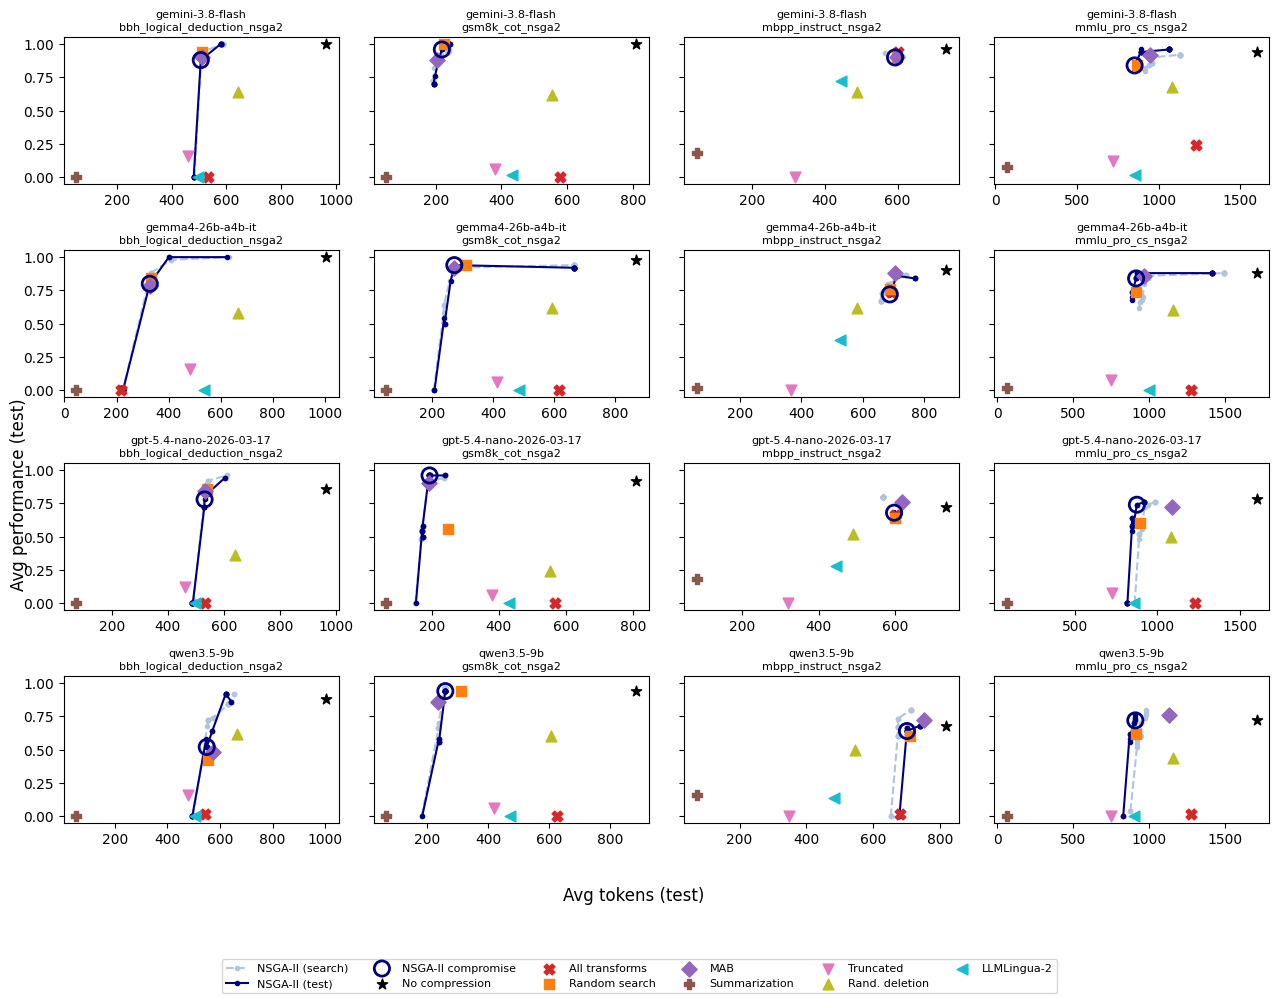

In [3]:
STYLE = {
    "no_compression": ("*", "black"), "all_transformations": ("X", "tab:red"),
    "random_search": ("s", "tab:orange"), "multi_armed_bandit": ("D", "tab:purple"),
    "summarization": ("P", "tab:brown"), "truncated_prompt": ("v", "tab:pink"),
    "random_deletion": ("^", "tab:olive"), "llmlingua2": ("<", "tab:cyan"),
}
fig, axes = plt.subplots(len(MODELS), len(TASKS), figsize=(COL2, ROW_H * len(MODELS)),
                         squeeze=False, sharey=True)
for r in runs:
    ax = axes[MODELS.index(r.model)][TASKS.index(r.name)]
    for split, style, color in (("search", "o--", "lightsteelblue"), ("test", "o-", "navy")):
        pts = sorted((s[f"{split}_avg_tokens"], s[f"{split}_avg_performance"]) for s in r.solutions(r.algorithm))
        ax.plot(*zip(*pts), style, color=color, ms=3, label=f"NSGA-II ({split})")
    i, sol = select_compromise(r, r.algorithm, SELECTION)
    ax.scatter(sol["test_avg_tokens"], sol["test_avg_performance"], s=120, facecolors="none",
               edgecolors="navy", linewidths=2, label="NSGA-II compromise", zorder=6)
    for b in r.data["baselines"]:
        marker, color = STYLE.get(b["name"], ("o", "gray"))
        if b["name"] in ("random_search", "multi_armed_bandit"):
            _, bs = select_compromise(r, b["name"], SELECTION)
            ax.scatter(bs["test_avg_tokens"], bs["test_avg_performance"], marker=marker, color=color,
                       s=60, label=METHOD_LABELS[b["name"]], zorder=5)
        else:
            ax.scatter(b["test_avg_tokens"], b["test_avg_performance"], marker=marker, color=color,
                       s=60, label=METHOD_LABELS.get(b["name"], b["name"]), zorder=5)
    ax.set_title(f"{r.model}\n{r.name}", fontsize=8)
    ax.set_ylim(-0.05, 1.05)
handles, labels = axes[0][0].get_legend_handles_labels()
fig.supxlabel("Avg tokens (test)", y=0.09); fig.supylabel("Avg performance (test)")
fig.legend(handles, labels, loc="lower center", ncol=6, fontsize=8)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig(FIG_DIR / "rq1_pareto_grid.pdf", bbox_inches="tight")

### RQ1 — per-run tests: compromise vs uncompressed prompt (paired over test samples)

In [4]:
rows = []
for r in runs:
    i, _ = select_compromise(r, r.algorithm, SELECTION)
    a = per_sample(r, r.algorithm, i)
    b = per_sample(r, "no_compression")
    m = a.merge(b, on="sample_id", suffixes=("_c", "_nc"))
    binary = set(np.unique(m[["score_c", "score_nc"]].to_numpy())) <= {0.0, 1.0}
    if binary:
        n01 = int(((m.score_c == 1) & (m.score_nc == 0)).sum()); n10 = int(((m.score_c == 0) & (m.score_nc == 1)).sum())
        p_perf = binomtest(min(n01, n10), n01 + n10).pvalue if n01 + n10 else 1.0
    else:
        p_perf = wilcoxon(m.score_c, m.score_nc).pvalue if (m.score_c != m.score_nc).any() else 1.0
    rows.append({
        "model": r.model, "task": r.name, "n": len(m),
        "perf_compromise": m.score_c.mean(), "perf_uncompressed": m.score_nc.mean(),
        "delta_perf": m.score_c.mean() - m.score_nc.mean(),
        "test": "exact McNemar" if binary else "Wilcoxon", "p_perf": p_perf,
        "tokens_compromise": m.tokens_c.mean(), "tokens_uncompressed": m.tokens_nc.mean(),
        "token_reduction": 1 - m.tokens_c.mean() / m.tokens_nc.mean(),
        "p_tokens": wilcoxon(m.tokens_c, m.tokens_nc).pvalue if (m.tokens_c != m.tokens_nc).any() else 1.0,
    })
df_rq1 = pd.DataFrame(rows)
display(df_rq1.round(3))
df_rq1.to_csv(FIG_DIR / "rq1_statistical_tests.csv", index=False)

,model,task,n,perf_compromise,perf_uncompressed,delta_perf,test,p_perf,tokens_compromise,tokens_uncompressed,token_reduction,p_tokens
0,gemini-3.8-flash,bbh_logical_deduction_nsga2,50,0.88,1.00,-0.12,exact McNemar,0.031,506.44,964.76,0.475,0.0
1,gemini-3.8-flash,gsm8k_cot_nsga2,50,0.96,1.00,-0.04,exact McNemar,0.500,218.36,810.32,0.731,0.0
2,gemini-3.8-flash,mbpp_instruct_nsga2,50,0.90,0.96,-0.06,exact McNemar,0.375,593.12,733.98,0.192,0.0
3,gemini-3.8-flash,mmlu_pro_cs_nsga2,50,0.84,0.94,-0.10,exact McNemar,0.062,853.38,1600.38,0.467,0.0
4,gemma4-26b-a4b-it,bbh_logical_deduction_nsga2,50,0.80,1.00,-0.20,exact McNemar,0.002,327.96,1005.28,0.674,0.0
5,gemma4-26b-a4b-it,gsm8k_cot_nsga2,50,0.94,0.98,-0.04,exact McNemar,0.500,272.26,868.72,0.687,0.0
6,gemma4-26b-a4b-it,mbpp_instruct_nsga2,50,0.72,0.90,-0.18,exact McNemar,0.004,687.82,871.54,0.211,0.0
7,gemma4-26b-a4b-it,mmlu_pro_cs_nsga2,50,0.84,0.88,-0.04,exact McNemar,0.625,915.82,1708.66,0.464,0.0
8,gpt-5.4-nano-2026-03-17,bbh_logical_deduction_nsga2,50,0.78,0.86,-0.08,exact McNemar,0.481,531.44,964.76,0.449,0.0
9,gpt-5.4-nano-2026-03-17,gsm8k_cot_nsga2,50,0.96,0.92,0.04,exact McNemar,0.500,193.72,810.32,0.761,0.0


---
## RQ2 — Comparison with baselines (points)

In [5]:
points = method_points(runs, selection=SELECTION)
assert not points["legacy_front_mean"].any(), "Legacy results: RS/MAB solutions not saved."
summary = (points.groupby("method")[["test_performance", "test_tokens", "compression", "utility"]]
           .mean().rename(index=METHOD_LABELS).sort_values("test_performance", ascending=False))
display(summary.round(3))
omni, post = [], []
for metric, hib in (("test_performance", True), ("compression", True), ("utility", True)):
    o, p = compare_methods(points, metric, higher_is_better=hib)
    omni.append(o); post.append(p)
df_omni, df_post = pd.DataFrame(omni), pd.concat(post, ignore_index=True)
display(df_omni.round(4)); display(df_post.round(4))
df_omni.to_csv(FIG_DIR / "rq2_friedman_tests.csv", index=False)
df_post.to_csv(FIG_DIR / "rq2_holm_wilcoxon_posthoc.csv", index=False)

,test_performance,test_tokens,compression,utility
method,,,,
No compression,0.885,1067.838,0.000,0.885
MAB,0.818,604.122,0.441,1.259
NSGA-II,0.804,562.032,0.470,1.274
Random search,0.762,576.331,0.455,1.217
Rand. deletion,0.549,719.544,0.327,0.876
All transforms,0.165,737.142,0.314,0.479
LLMLingua-2,0.098,585.601,0.449,0.547
Truncated,0.070,485.718,0.544,0.614
Summarization,0.040,62.268,0.937,0.977


,metric,n_cells,n_methods,chi2,p,kendall_w
0,test_performance,16,9,104.4573,0.0,0.8161
1,compression,16,9,91.9020,0.0,0.7180
2,utility,16,9,86.9161,0.0,0.6790


,metric,baseline,alternative,reference_median,baseline_median,wins,losses,rank_biserial,p_raw,p_holm
0,test_performance,all_transformations,greater,0.8200,0.0000,14,2,0.9338,0.0005,0.0020
1,test_performance,llmlingua2,greater,0.8200,0.0000,16,0,1.0000,0.0002,0.0017
2,test_performance,multi_armed_bandit,greater,0.8200,0.8600,7,8,-0.2333,0.7878,0.7878
3,test_performance,no_compression,two-sided,0.8200,0.9100,1,13,-0.9714,0.0013,0.0039
4,test_performance,random_deletion,greater,0.8200,0.6000,15,1,0.9779,0.0003,0.0017
5,test_performance,random_search,greater,0.8200,0.8000,7,5,0.4615,0.0781,0.1562
6,test_performance,summarization,greater,0.8200,0.0000,16,0,1.0000,0.0002,0.0017
7,test_performance,truncated_prompt,greater,0.8200,0.0600,16,0,1.0000,0.0002,0.0017
8,compression,all_transformations,greater,0.4654,0.2698,13,3,0.7353,0.0038,0.0229
9,compression,llmlingua2,greater,0.4654,0.4651,7,9,0.0882,0.3910,1.0000


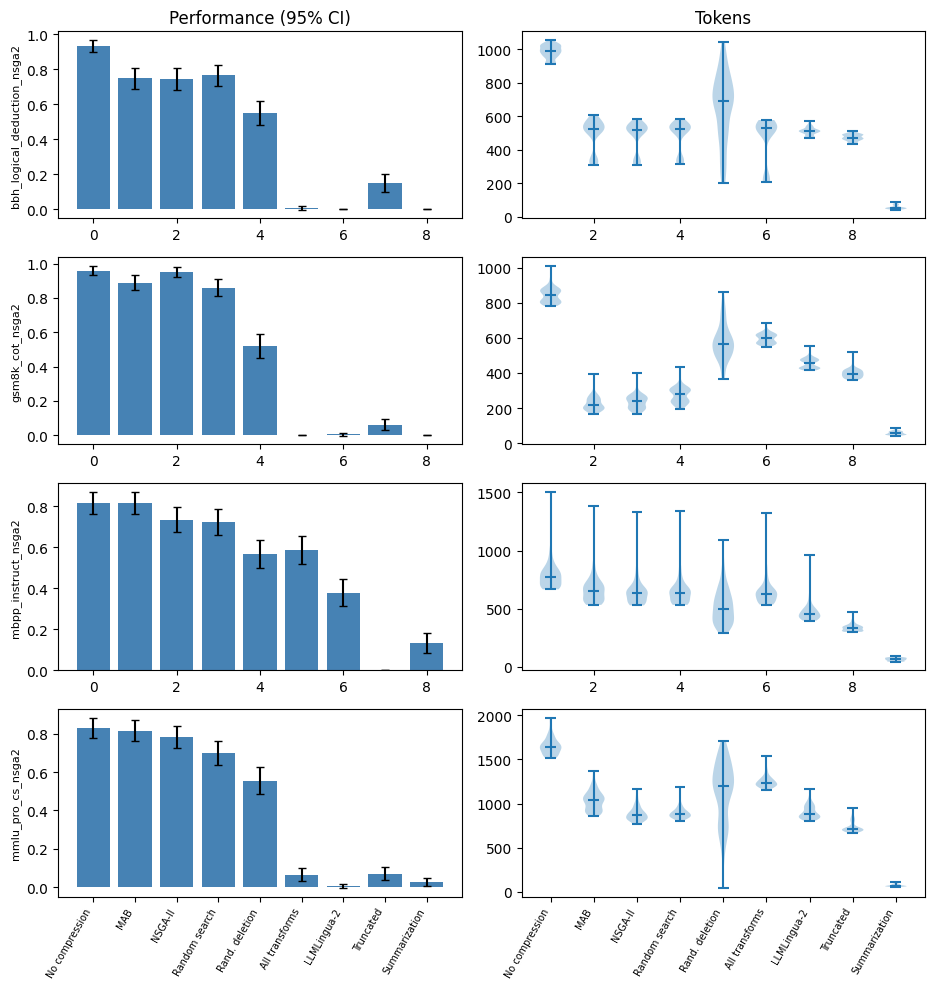

In [6]:
# Per-sample distributions of every method's point, pooled across models, per task.
per = []
for r in runs:
    for _, row in points[(points.model == r.model) & (points.task == r.name)].iterrows():
        d = per_sample(r, row.method, int(row.solution_index))
        d["task"], d["method"] = r.name, row.label
        per.append(d)
per = pd.concat(per, ignore_index=True)
order = list(summary.index)
fig, axes = plt.subplots(len(TASKS), 2, figsize=(COL1 * 1.5, ROW_H * len(TASKS)), squeeze=False)
for ti, task in enumerate(TASKS):
    sub = per[per.task == task]
    means = [sub[sub.method == m].score.mean() for m in order]
    ci = [1.96 * sub[sub.method == m].score.std(ddof=1) / np.sqrt(max((sub.method == m).sum(), 1)) for m in order]
    axes[ti][0].bar(range(len(order)), means, yerr=ci, capsize=3, color="steelblue")
    axes[ti][1].violinplot([sub[sub.method == m].tokens for m in order], showmedians=True)
    axes[ti][0].set_ylabel(task, fontsize=8)
for ax in axes[-1]:
    ax.set_xticks(range(len(order)) if ax is axes[-1][0] else range(1, len(order) + 1))
    ax.set_xticklabels(order, rotation=60, ha="right", fontsize=7)
axes[0][0].set_title("Performance (95% CI)"); axes[0][1].set_title("Tokens")
fig.tight_layout()
fig.savefig(FIG_DIR / "rq2_distributions.pdf", bbox_inches="tight")

---
## RQ3 — Cost and convergence

search_llm_calls  \
model                   task                                            
gemini-3.8-flash        bbh_logical_deduction_nsga2             29021   
                        gsm8k_cot_nsga2                         29892   
                        mbpp_instruct_nsga2                     10267   
                        mmlu_pro_cs_nsga2                       38560   
gemma4-26b-a4b-it       bbh_logical_deduction_nsga2             30315   
                        gsm8k_cot_nsga2                         32945   
                        mbpp_instruct_nsga2                     12044   
                        mmlu_pro_cs_nsga2                       39883   
gpt-5.4-nano-2026-03-17 bbh_logical_deduction_nsga2             36750   
                        gsm8k_cot_nsga2                         35782   
                        mbpp_instruct_nsga2                     10437   
                        mmlu_pro_cs_nsga2                       36039   
qwen3.5-9b              bbh_logical_deduction_nsga2             34810   
                        gsm8k_cot_nsga2                         31165   
                        mbpp_instruct_nsga2                      9987   
                        mmlu_pro_cs_nsga2                       36847   

                                                     search_input_tokens  \
model                   task                                               
gemini-3.8-flash        bbh_logical_deduction_nsga2             18088463   
                        gsm8k_cot_nsga2                         15733075   
                        mbpp_instruct_nsga2                      6345544   
                        mmlu_pro_cs_nsga2                       53680295   
gemma4-26b-a4b-it       bbh_logical_deduction_nsga2             16273169   
                        gsm8k_cot_nsga2                         17493387   
                        mbpp_instruct_nsga2                      9056070   
                        mmlu_pro_cs_nsga2                       59559617   
gpt-5.4-nano-2026-03-17 bbh_logical_deduction_nsga2             23550602   
                        gsm8k_cot_nsga2                         20052553   
                        mbpp_instruct_nsga2                      6640101   
                        mmlu_pro_cs_nsga2                       50815223   
qwen3.5-9b              bbh_logical_deduction_nsga2             23494528   
                        gsm8k_cot_nsga2                         16643951   
                        mbpp_instruct_nsga2                      7316126   
                        mmlu_pro_cs_nsga2                       55104269   

                                                     search_output_tokens  \
model                   task                                                
gemini-3.8-flash        bbh_logical_deduction_nsga2              11283896   
                        gsm8k_cot_nsga2                           3672737   
                        mbpp_instruct_nsga2                       2534006   
                        mmlu_pro_cs_nsga2                         7558439   
gemma4-26b-a4b-it       bbh_logical_deduction_nsga2              28284173   
                        gsm8k_cot_nsga2                           7773092   
                        mbpp_instruct_nsga2                       4989664   
                        mmlu_pro_cs_nsga2                        24400452   
gpt-5.4-nano-2026-03-17 bbh_logical_deduction_nsga2              17773391   
                        gsm8k_cot_nsga2                           5467918   
                        mbpp_instruct_nsga2                       3604016   
                        mmlu_pro_cs_nsga2                         8203496   
qwen3.5-9b              bbh_logical_deduction_nsga2              46871277   
                        gsm8k_cot_nsga2                           8580999   
                        mbpp_instruct_nsga2                       3481428   
                        mmlu_pro_cs_nsga2                   

Break-even (input tokens) median: 48915.76624755062


,candidates,distinct_prompt_sets,standalone_llm_calls,llm_calls_made_in_run
method,,,,
all_transformations,1.0,1.0,41.2,41.2
llmlingua2,1.0,1.0,41.2,41.2
multi_armed_bandit,300.0,258.6,9972.8,9972.8
no_compression,1.0,1.0,41.2,41.2
nsga2,300.0,162.6,5893.8,5893.8
random_deletion,1.0,1.0,41.2,41.2
random_search,300.0,299.5,12307.5,12307.5
summarization,1.0,1.0,41.2,41.2
truncated_prompt,1.0,1.0,41.2,41.2


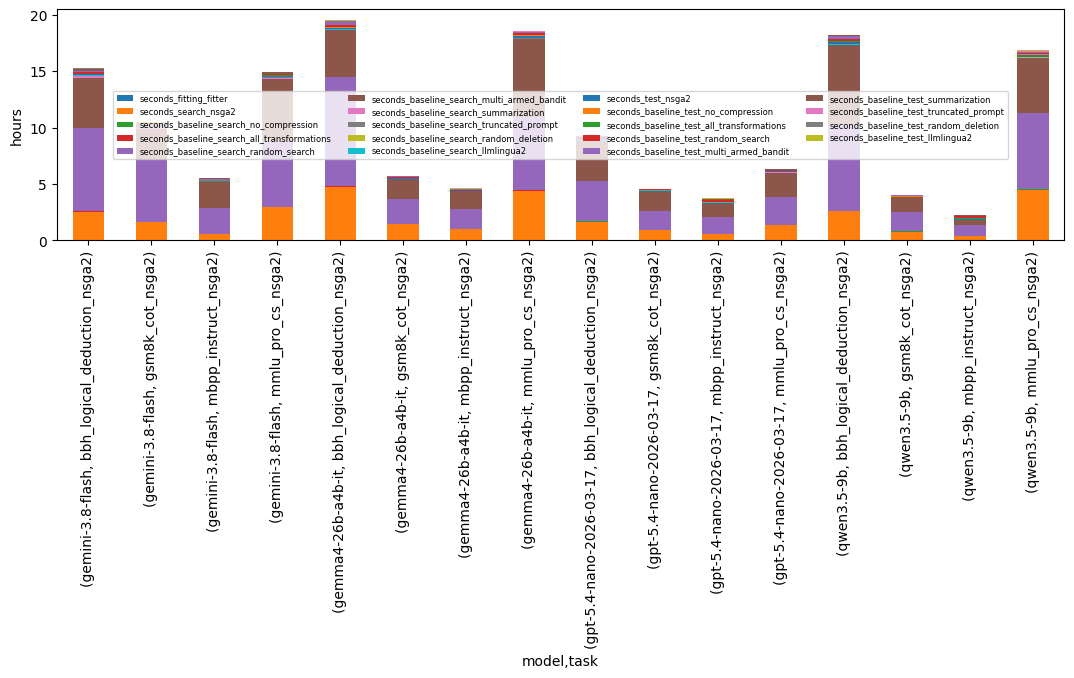

In [7]:
df_cost = pd.DataFrame([cost(r) for r in runs])
nsga = points[points.method == "nsga2"].set_index(["model", "task"])
nc = points[points.method == "no_compression"].set_index(["model", "task"])
df_cost = df_cost.set_index(["model", "task"])
df_cost["saved_tokens_per_query"] = nc.test_tokens - nsga.test_tokens
df_cost["break_even_queries"] = df_cost.search_input_tokens / df_cost.saved_tokens_per_query
display(df_cost.round(1))
print("Break-even (input tokens) median:", df_cost.break_even_queries.median())
df_cost.to_csv(FIG_DIR / "rq3_cost.csv")
time_cols = [c for c in df_cost.columns if c.startswith("seconds_")]
ax = (df_cost[time_cols] / 3600).plot.bar(stacked=True, figsize=(COL2, 3), legend=False)
ax.set_ylabel("hours"); ax.legend(fontsize=6, ncol=4)
plt.tight_layout(); plt.savefig(FIG_DIR / "rq3_time_by_phase.pdf", bbox_inches="tight")

# Calls each search method needs on its own: methods share one evaluation cache per run,
# so logged calls and wall-clock times understate the cost of methods that run later.
df_standalone = pd.concat([standalone_cost(r) for r in runs], ignore_index=True)
display(df_standalone.groupby("method")[["candidates", "distinct_prompt_sets",
                                         "standalone_llm_calls", "llm_calls_made_in_run"]].mean().round(1))
df_standalone.to_csv(FIG_DIR / "rq3_standalone_cost.csv", index=False)

method                                               multi_armed_bandit  \
model                   task                                              
gemini-3.8-flash        bbh_logical_deduction_nsga2                  30   
                        gsm8k_cot_nsga2                              17   
                        mbpp_instruct_nsga2                          15   
                        mmlu_pro_cs_nsga2                           224   
gemma4-26b-a4b-it       bbh_logical_deduction_nsga2                  46   
                        gsm8k_cot_nsga2                              22   
                        mbpp_instruct_nsga2                          40   
                        mmlu_pro_cs_nsga2                           132   
gpt-5.4-nano-2026-03-17 bbh_logical_deduction_nsga2                  98   
                        gsm8k_cot_nsga2                              35   
                        mbpp_instruct_nsga2                          45   
                        mmlu_pro_cs_nsga2                           267   
qwen3.5-9b              bbh_logical_deduction_nsga2                 161   
                        gsm8k_cot_nsga2                              30   
                        mbpp_instruct_nsga2                         141   
                        mmlu_pro_cs_nsga2                            27   

method                                               nsga2  random_search  
model                   task                                               
gemini-3.8-flash        bbh_logical_deduction_nsga2      3            187  
                        gsm8k_cot_nsga2                  2             38  
                        mbpp_instruct_nsga2              2             43  
                        mmlu_pro_cs_nsga2                4             38  
gemma4-26b-a4b-it       bbh_logical_deduction_nsga2      5            243  
                        gsm8k_cot_nsga2                  4            279  
                        mbpp_instruct_nsga2              6             25  
                        mmlu_pro_cs_nsga2                5             38  
gpt-5.4-nano-2026-03-17 bbh_logical_deduction_nsga2      4            130  
                        gsm8k_cot_nsga2                  7            139  
                        mbpp_instruct_nsga2              9              8  
                        mmlu_pro_cs_nsga2                6            220  
qwen3.5-9b              bbh_logical_deduction_nsga2      3            187  
                        gsm8k_cot_nsga2                  4            279  
                        mbpp_instruct_nsga2              3             75  
                        mmlu_pro_cs_nsga2                6            201

method                                               multi_armed_bandit  \
model                   task                                              
gemini-3.8-flash        bbh_logical_deduction_nsga2               0.461   
                        gsm8k_cot_nsga2                           0.752   
                        mbpp_instruct_nsga2                       0.179   
                        mmlu_pro_cs_nsga2                         0.387   
gemma4-26b-a4b-it       bbh_logical_deduction_nsga2               0.663   
                        gsm8k_cot_nsga2                           0.670   
                        mbpp_instruct_nsga2                       0.172   
                        mmlu_pro_cs_nsga2                         0.373   
gpt-5.4-nano-2026-03-17 bbh_logical_deduction_nsga2               0.441   
                        gsm8k_cot_nsga2                           0.699   
                        mbpp_instruct_nsga2                       0.134   
                        mmlu_pro_cs_nsga2                         0.241   
qwen3.5-9b              bbh_logical_deduction_nsga2               0.378   
                        gsm8k_cot_nsga2                           0.693   
                        mbpp_instruct_nsga2                       0.092   
                        mmlu_pro_cs_nsga2                         0.258   

method                                               nsga2  random_search  
model                   task                                               
gemini-3.8-flash        bbh_logical_deduction_nsga2  0.466          0.467  
                        gsm8k_cot_nsga2              0.753          0.750  
                        mbpp_instruct_nsga2          0.173          0.172  
                        mmlu_pro_cs_nsga2            0.446          0.404  
gemma4-26b-a4b-it       bbh_logical_deduction_nsga2  0.661          0.657  
                        gsm8k_cot_nsga2              0.670          0.664  
                        mbpp_instruct_nsga2          0.180          0.173  
                        mmlu_pro_cs_nsga2            0.420          0.386  
gpt-5.4-nano-2026-03-17 bbh_logical_deduction_nsga2  0.414          0.398  
                        gsm8k_cot_nsga2              0.747          0.551  
                        mbpp_instruct_nsga2          0.127          0.137  
                        mmlu_pro_cs_nsga2            0.356          0.308  
qwen3.5-9b              bbh_logical_deduction_nsga2  0.395          0.381  
                        gsm8k_cot_nsga2              0.678          0.692  
                        mbpp_instruct_nsga2          0.098          0.095  
                        mmlu_pro_cs_nsga2            0.369          0.332

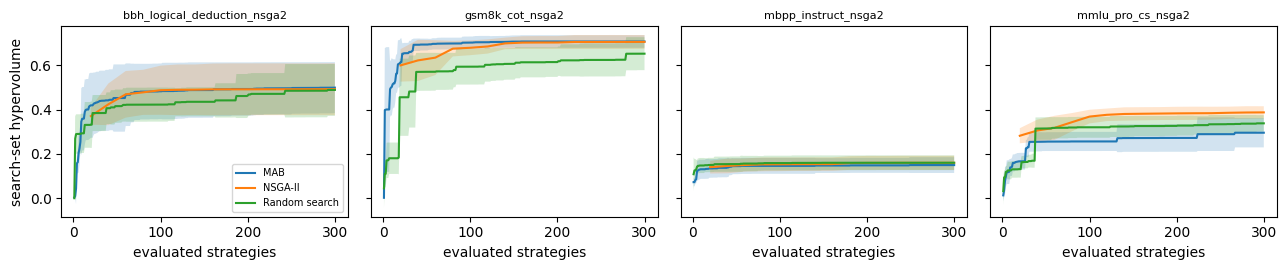

In [8]:
conv = []
for r in runs:
    c = convergence(r); c["model"], c["task"] = r.model, r.name
    conv.append(c)
conv = pd.concat(conv, ignore_index=True)
fig, axes = plt.subplots(1, len(TASKS), figsize=(COL2, 2.8), squeeze=False, sharey=True)
for ti, task in enumerate(TASKS):
    ax = axes[0][ti]
    for method, g in conv[conv.task == task].groupby("method"):
        curve = g.groupby("n_visited").hypervolume.agg(["mean", "std"]).reset_index()
        ax.plot(curve.n_visited, curve["mean"], label=METHOD_LABELS.get(method, method))
        ax.fill_between(curve.n_visited, curve["mean"] - curve["std"].fillna(0),
                        curve["mean"] + curve["std"].fillna(0), alpha=0.2)
    ax.set_title(task, fontsize=8); ax.set_xlabel("evaluated strategies")
axes[0][0].set_ylabel("search-set hypervolume"); axes[0][0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG_DIR / "rq3_convergence.pdf", bbox_inches="tight")

final = conv.groupby(["model", "task", "method"]).hypervolume.transform("max")
conv["reached_95"] = conv.hypervolume >= 0.95 * final
first95 = (conv[conv.reached_95].groupby(["model", "task", "method"]).step.min().rename("step_95pct_hv"))
display(first95.unstack("method"))
first95.to_csv(FIG_DIR / "rq3_convergence_descriptors.csv")

hv = pd.DataFrame([{"model": r.model, "task": r.name, "method": m, "test_hv": front_hypervolume(r, m)}
                   for r in runs for m in ("nsga2", "random_search", "multi_armed_bandit") if r.solutions(m)])
display(hv.pivot_table(index=["model", "task"], columns="method", values="test_hv").round(3))

---
## RQ4 — Operator patterns and transferability

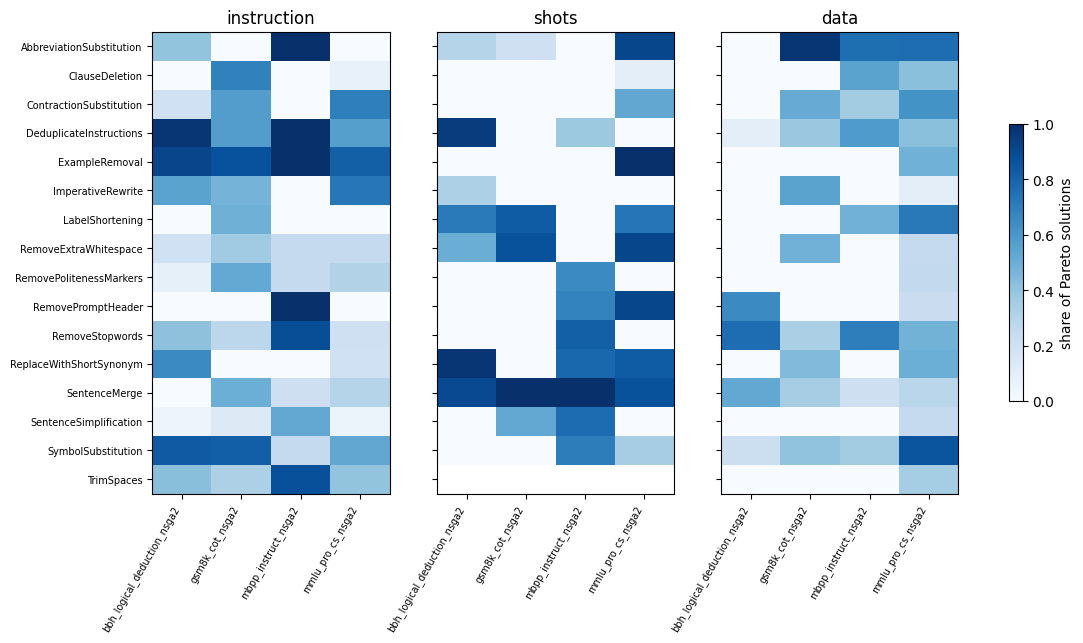

In [9]:
freq = operator_frequency(runs)
fig, axes = plt.subplots(1, 3, figsize=(COL2, 6), sharey=True)
for ax, section in zip(axes, ("instruction", "shots", "data")):
    m = freq[freq.section == section].pivot_table(index="operator", columns="task", values="frequency", aggfunc="mean").fillna(0)
    im = ax.imshow(m.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="Blues")
    ax.set_title(section); ax.set_xticks(range(m.shape[1])); ax.set_xticklabels(m.columns, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(m.shape[0])); ax.set_yticklabels(m.index, fontsize=7)
fig.colorbar(im, ax=axes, shrink=0.6, label="share of Pareto solutions")
fig.savefig(FIG_DIR / "rq4_2_operators.pdf", bbox_inches="tight")
freq.to_csv(FIG_DIR / "rq4_operator_frequency.csv", index=False)

In [10]:
transfers = load_transfers(RESULTS_DIR)
if transfers.empty:
    print("No transfer results.")
else:
    native = pd.DataFrame([{"model": r.model, "target": r.name,
                            "native_tokens": np.mean([s["test_avg_tokens"] for s in r.solutions(r.algorithm)]),
                            "native_performance": np.mean([s["test_avg_performance"] for s in r.solutions(r.algorithm)])}
                           for r in runs])
    t = (transfers.groupby(["model", "source", "target"])[["test_tokens", "test_performance"]].mean()
         .reset_index().merge(native, on=["model", "target"]))
    display(t.round(3)); t.to_csv(FIG_DIR / "rq4_transfer.csv", index=False)

,model,source,target,test_tokens,test_performance,native_tokens,native_performance
0,gemini-3.8-flash,bbh_logical_deduction_nsga2,gsm8k_cot_nsga2,377.190,0.742,222.572,0.907
1,gemini-3.8-flash,gsm8k_cot_nsga2,bbh_logical_deduction_nsga2,554.798,0.474,521.636,0.696
2,gemma4-26b-a4b-it,bbh_logical_deduction_nsga2,gsm8k_cot_nsga2,691.752,0.278,466.901,0.756
3,gemma4-26b-a4b-it,gsm8k_cot_nsga2,bbh_logical_deduction_nsga2,561.414,0.263,280.999,0.315
4,gpt-5.4-nano-2026-03-17,bbh_logical_deduction_nsga2,gsm8k_cot_nsga2,561.934,0.281,187.273,0.742
5,gpt-5.4-nano-2026-03-17,gsm8k_cot_nsga2,bbh_logical_deduction_nsga2,566.752,0.542,516.972,0.400
6,qwen3.5-9b,bbh_logical_deduction_nsga2,gsm8k_cot_nsga2,379.850,0.342,249.916,0.793
7,qwen3.5-9b,gsm8k_cot_nsga2,bbh_logical_deduction_nsga2,591.822,0.461,569.116,0.559


---
## Numbers for the paper

In [11]:
s = summary
print(f"Selection on: {SELECTION}")
print(f"NSGA-II compromise: perf {s.loc['NSGA-II','test_performance']:.3f} at {s.loc['NSGA-II','test_tokens']:.0f} tokens "
      f"vs no compression {s.loc['No compression','test_performance']:.3f} at {s.loc['No compression','test_tokens']:.0f} "
      f"({1 - s.loc['NSGA-II','test_tokens'] / s.loc['No compression','test_tokens']:.1%} fewer tokens)")
print("Per-task NSGA-II vs no compression (mean over models):")
display(points[points.method.isin(["nsga2", "no_compression"])]
        .pivot_table(index="task", columns="method", values=["test_performance", "test_tokens"]).round(3))

Selection on: search
NSGA-II compromise: perf 0.804 at 562 tokens vs no compression 0.885 at 1068 (47.4% fewer tokens)
Per-task NSGA-II vs no compression (mean over models):


test_performance           test_tokens         
method                        no_compression  nsga2 no_compression    nsga2
task                                                                       
bbh_logical_deduction_nsga2            0.935  0.745        984.500  478.930
gsm8k_cot_nsga2                        0.960  0.950        843.570  235.935
mbpp_instruct_nsga2                    0.815  0.735        789.765  644.915
mmlu_pro_cs_nsga2                      0.830  0.785       1653.515  888.350